### NO 1 users_data_cleaned.pickle

1. Load and preview the data

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_pickle("users_data_cleaned.pickle")

display(df.head())
print("Ukuran data:", df.shape)

,user_id,number_transactions,total_amount_usd,age,job,marital,education,default,housing,loan,contact,duration,campaign,pdays,previous,poutcome,term_deposit,date_joined,device
0,9231c446-cb16-4b2b-a7f7-ddfc8b25aaf6,3.0,2143.0,58,management,married,tertiary,False,True,False,None,261,1,-1,0,None,False,1998-08-23,mobile
1,bb92765a-08de-4963-b432-496524b39157,NaN,NaN,44,technician,single,secondary,False,True,False,None,151,1,-1,0,None,False,2008-07-15,desktop
2,573de577-49ef-42b9-83da-d3cfb817b5c1,2.0,2.0,33,entrepreneur,married,secondary,False,True,True,None,76,1,-1,0,None,False,2002-06-04,mobile
3,d6b66b9d-7c8f-4257-a682-e136f640b7e3,NaN,NaN,47,blue-collar,married,None,False,True,False,None,92,1,-1,0,None,False,1995-06-29,tablet
4,fade0b20-7594-4d9a-84cd-c02f79b1b526,1.0,1.0,33,None,single,None,False,False,False,None,198,1,-1,0,None,False,1995-08-01,mobile


Ukuran data: (45209, 19)


Kode digunakan untuk membaca dataset users_data_cleaned.pickle menggunakan Pandas dan menampilkan lima baris pertama untuk melihat gambaran awal data.

2. Check the shape of the data

In [4]:
print("Jumlah baris dan kolom:", df.shape)

Jumlah baris dan kolom: (45209, 19)


Kode digunakan untuk mengetahui jumlah baris dan kolom dalam dataset. Output menunjukkan ukuran data dalam format (jumlah baris, jumlah kolom).

3. Check the data types

In [5]:
print(df.dtypes)

user_id                        object
number_transactions           float64
total_amount_usd              float64
age                             int64
job                            object
marital                        object
education                      object
default                          bool
housing                          bool
loan                             bool
contact                        object
duration                        int64
campaign                        int64
pdays                           int64
previous                        int64
poutcome                       object
term_deposit                     bool
date_joined            datetime64[ns]
device                         object
dtype: object


Kode digunakan untuk mengetahui tipe data setiap kolom, misalnya integer, float, object, atau boolean. Hal ini membantu memastikan tipe data sesuai dengan kebutuhan analisis.

4. Check for correlations

In [6]:
corr = df.select_dtypes(include="number").corr()
display(corr)

,number_transactions,total_amount_usd,age,duration,campaign,pdays,previous
number_transactions,1.000000,-0.163409,-0.008813,-0.017220,0.026431,-0.030751,-0.023046
total_amount_usd,-0.163409,1.000000,0.095839,0.022586,-0.017274,0.006435,0.016952
age,-0.008813,0.095839,1.000000,-0.004645,0.004767,-0.023745,0.001297
duration,-0.017220,0.022586,-0.004645,1.000000,-0.084551,-0.001549,0.001213
campaign,0.026431,-0.017274,0.004767,-0.084551,1.000000,-0.088636,-0.032860
pdays,-0.030751,0.006435,-0.023745,-0.001549,-0.088636,1.000000,0.454817
previous,-0.023046,0.016952,0.001297,0.001213,-0.032860,0.454817,1.000000


Kode digunakan untuk mengetahui hubungan antarvariabel numerik. Nilai korelasi mendekati 1 menunjukkan hubungan positif yang kuat, mendekati -1 menunjukkan hubungan negatif yang kuat, dan mendekati 0 menunjukkan hubungan linear yang lemah.

5. Generate summary statistics for numerical data only


In [7]:
display(df.describe(include="number"))

,number_transactions,total_amount_usd,age,duration,campaign,pdays,previous
count,35210.000000,35210.000000,45209.000000,45209.000000,45209.000000,45209.000000,45209.000000
mean,3.977052,1369.417751,40.935853,258.153067,2.763897,40.199651,0.580349
std,3.814329,3063.412688,10.618653,257.525446,3.098076,100.130586,2.303489
min,1.000000,-8019.000000,18.000000,0.000000,1.000000,-1.000000,0.000000
25%,2.000000,73.000000,33.000000,103.000000,1.000000,-1.000000,0.000000
50%,3.000000,451.000000,39.000000,180.000000,2.000000,-1.000000,0.000000
75%,4.000000,1438.000000,48.000000,319.000000,3.000000,-1.000000,0.000000
max,20.000000,102127.000000,95.000000,4918.000000,63.000000,871.000000,275.000000


Kode digunakan untuk menampilkan statistik deskriptif data numerik, seperti rata-rata (mean), standar deviasi, nilai minimum, maksimum, dan kuartil.

6. Plot Histograms for all numerical columns

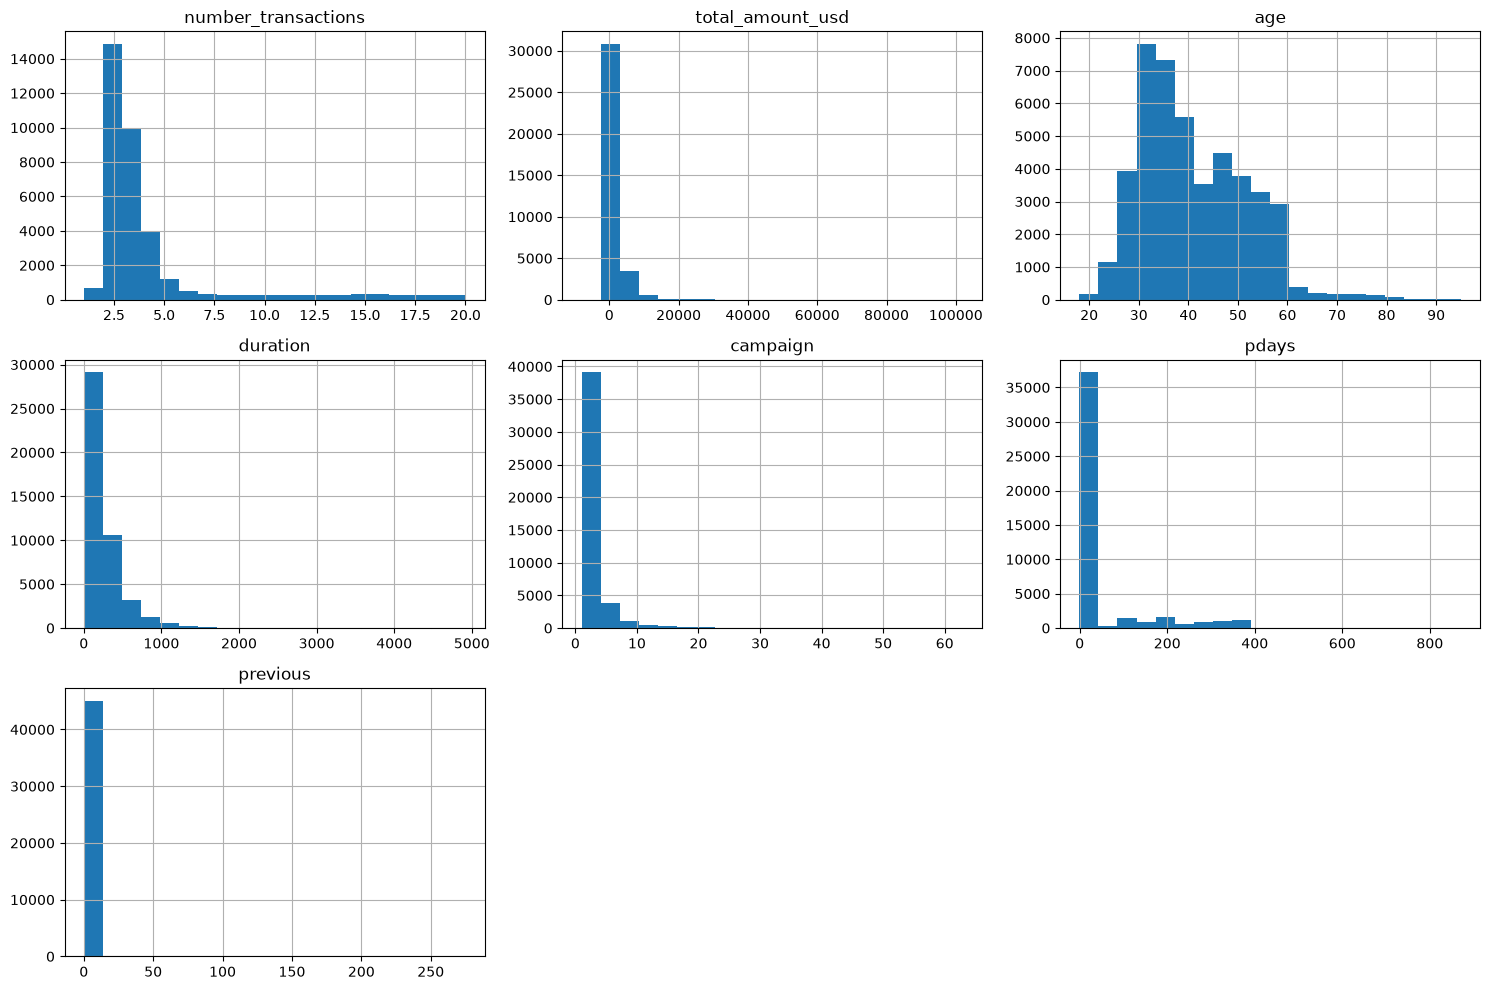

In [8]:
df.select_dtypes(include="number").hist(
    figsize=(15, 10),
    bins=20
)

plt.tight_layout()
plt.show()

Histogram digunakan untuk melihat distribusi atau penyebaran nilai pada setiap kolom numerik, sehingga pola data dan kemungkinan kemencengan distribusi dapat diamati.

7. Generate a box plot for age, dan number_transactions

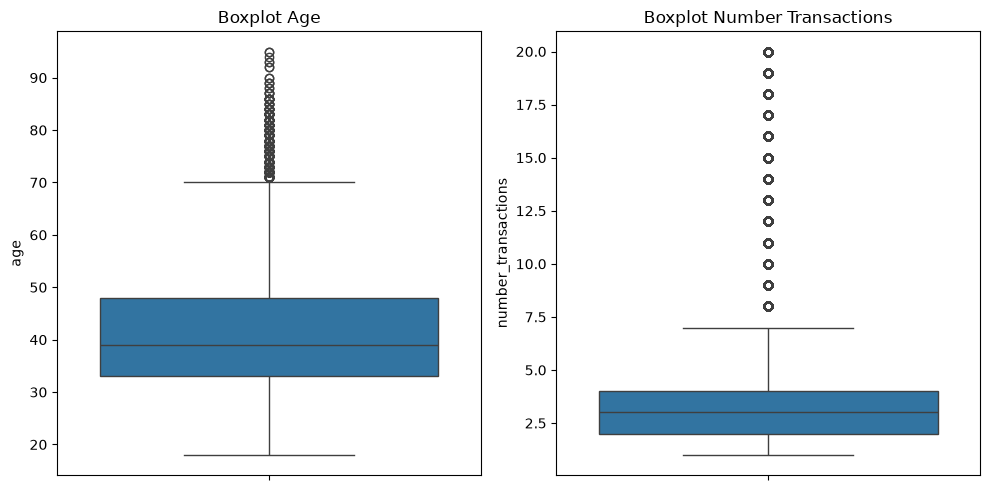

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.boxplot(y=df["age"], ax=axes[0])
axes[0].set_title("Boxplot Age")

sns.boxplot(y=df["number_transactions"], ax=axes[1])
axes[1].set_title("Boxplot Number Transactions")

plt.tight_layout()
plt.show()

Boxplot digunakan untuk melihat median, rentang penyebaran data, dan kemungkinan adanya pencilan (outlier) pada kolom age dan number_transactions.

8. Generate a lineplot for date_joined to total_amount_usd

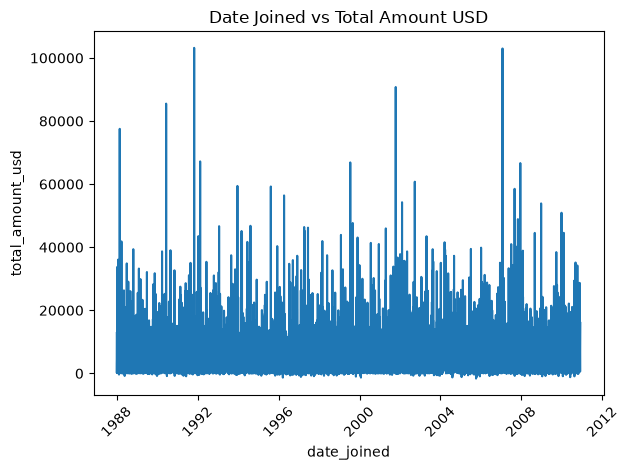

In [11]:
df["date_joined"] = pd.to_datetime(
    df["date_joined"], errors="coerce"
)

line_df = (
    df.dropna(subset=["date_joined"])
      .groupby("date_joined")["total_amount_usd"]
      .sum()
      .reset_index()
      .sort_values("date_joined")
)

sns.lineplot(
    data=line_df,
    x="date_joined",
    y="total_amount_usd"
)

plt.title("Date Joined vs Total Amount USD")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Lineplot digunakan untuk menggambarkan hubungan tanggal bergabung (date_joined) dengan total nilai transaksi (total_amount_usd). Pada kode tersebut, nilai USD dijumlahkan berdasarkan tanggal agar perubahan nilainya lebih mudah diamati.

9. Generate scatter plots comparing total_amount_usd to number_transaction

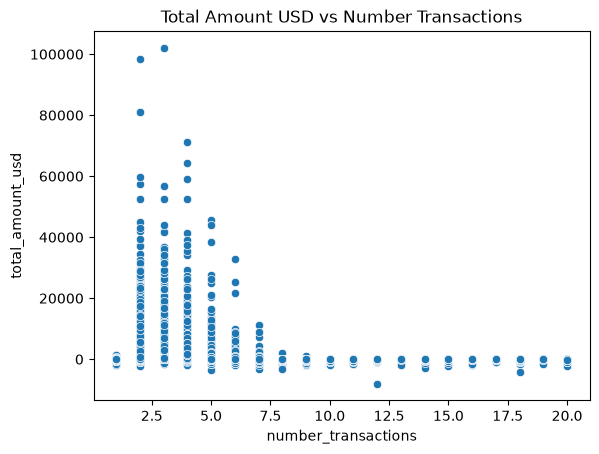

In [12]:
sns.scatterplot(
    data=df,
    x="number_transactions",
    y="total_amount_usd"
)

plt.title("Total Amount USD vs Number Transactions")
plt.show()

Scatterplot digunakan untuk melihat hubungan antara jumlah transaksi dan total nilai transaksi dalam USD. Setiap titik mewakili satu observasi, sehingga pola hubungan kedua variabel dapat diamati.

10. Generate Horizontal bar charts for job

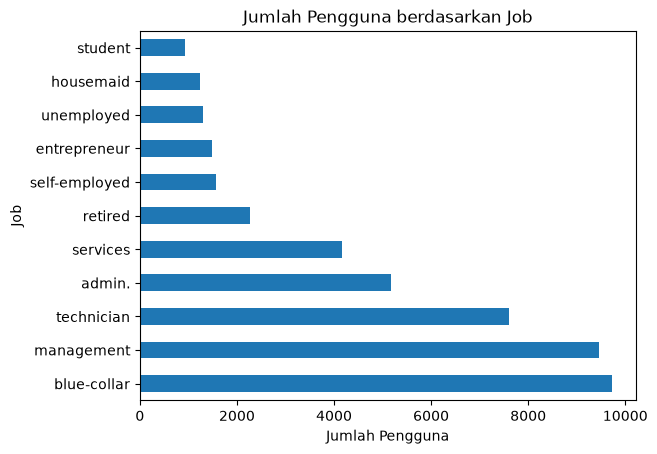

In [13]:
df["job"].value_counts().plot(kind="barh")

plt.title("Jumlah Pengguna berdasarkan Job")
plt.xlabel("Jumlah Pengguna")
plt.ylabel("Job")
plt.show()

Diagram batang horizontal digunakan untuk menampilkan jumlah pengguna berdasarkan jenis pekerjaan (job). Grafik ini memudahkan perbandingan jumlah pengguna pada setiap kategori pekerjaan.

11. Generate Horizontal bar charts for marital

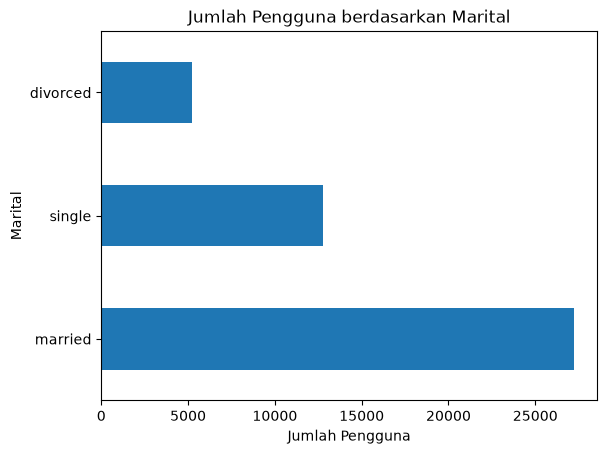

In [14]:
df["marital"].value_counts().plot(kind="barh")

plt.title("Jumlah Pengguna berdasarkan Marital")
plt.xlabel("Jumlah Pengguna")
plt.ylabel("Marital")
plt.show()

Diagram batang horizontal digunakan untuk menunjukkan jumlah pengguna berdasarkan status pernikahan (marital), sehingga jumlah pengguna pada setiap kategori dapat dibandingkan.

12. Generate a heatmap for future correlations

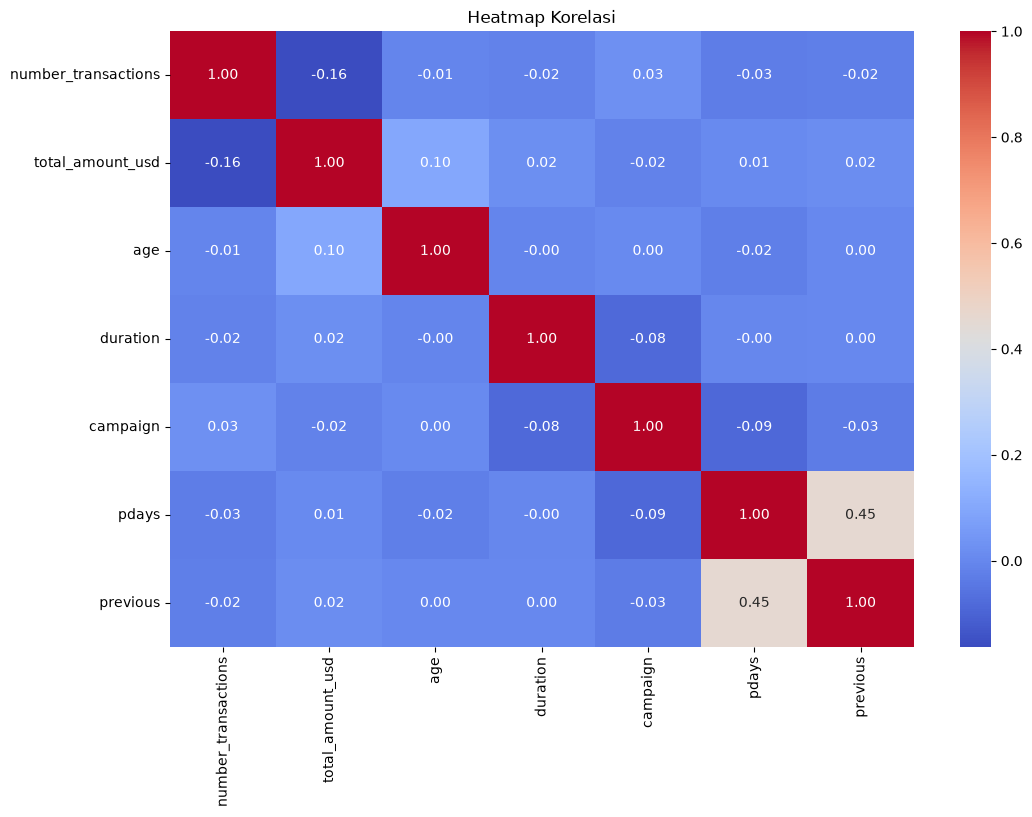

In [14]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Heatmap Korelasi")
plt.show()

Heatmap digunakan untuk memvisualisasikan matriks korelasi antarvariabel numerik dengan warna. Visualisasi ini membantu mengidentifikasi variabel yang memiliki hubungan kuat maupun lemah.

13. Identify Missing Values

In [15]:
print("Missing values setiap kolom:")
display(df.isnull().sum().to_frame("Jumlah Missing Values"))

print("Total missing values:", df.isnull().sum().sum())

Missing values setiap kolom:


,Jumlah Missing Values
user_id,0
number_transactions,9999
total_amount_usd,9999
age,0
job,288
marital,0
education,1857
default,0
housing,0
loan,0


Total missing values: 72242


Kode digunakan untuk menghitung jumlah nilai yang kosong (missing values) pada setiap kolom dan secara keseluruhan. Hasilnya membantu menentukan apakah data memerlukan penanganan lebih lanjut sebelum analisis.

### NO 2 dataset real_estate.csv yang berisikan informasi berupa transaksi, umur rumah, jarak ke stasiun, ketersediaan toko serba ada sekitar, dan titik kordinat.

a. Membaca file real_estate.csv

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('real_estate.csv')

display(df.head())

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1


Kode membaca dataset menggunakan Pandas. Parameter sep=";" digunakan karena kolom pada file dipisahkan dengan tanda titik koma.

2. Menampilkan variable dalam dataset

In [25]:
print("Nama variabel:")
print(df.columns.tolist())

print("\nInformasi dataset:")
df.info()

print("\nStatistik deskriptif:")
display(df.describe())

Nama variabel:
['No', 'X1 transaction date', 'X2 house age', 'X3 distance to the nearest MRT station', 'X4 number of convenience stores', 'X5 latitude', 'X6 longitude', 'Y house price of unit area']

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 8 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   No                                      414 non-null    int64  
 1   X1 transaction date                     414 non-null    float64
 2   X2 house age                            414 non-null    float64
 3   X3 distance to the nearest MRT station  414 non-null    float64
 4   X4 number of convenience stores         414 non-null    int64  
 5   X5 latitude                             414 non-null    float64
 6   X6 longitude                            414 non-null    float64
 7   Y house price of unit area              414 non-null    float6

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
count,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000
mean,207.500000,2013.148971,17.712560,1083.885689,4.094203,24.969030,121.533361,37.980193
std,119.655756,0.281967,11.392485,1262.109595,2.945562,0.012410,0.015347,13.606488
min,1.000000,2012.667000,0.000000,23.382840,0.000000,24.932070,121.473530,7.600000
25%,104.250000,2012.917000,9.025000,289.324800,1.000000,24.963000,121.528085,27.700000
50%,207.500000,2013.167000,16.100000,492.231300,4.000000,24.971100,121.538630,38.450000
75%,310.750000,2013.417000,28.150000,1454.279000,6.000000,24.977455,121.543305,46.600000
max,414.000000,2013.583000,43.800000,6488.021000,10.000000,25.014590,121.566270,117.500000


Kode menampilkan nama variabel dan informasi tipe data. Dataset ini memiliki dua variabel, yaitu BiayaPromo dan NilaiPenjualan.

c.	Menampilkan data yang di-split (train: 80 % & test:20%)

In [26]:
from sklearn.model_selection import train_test_split

X = df[['X3 distance to the nearest MRT station']]
y = df['Y house price of unit area']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

print("\nData training:")
display(X_train.head())

print("\nData testing:")
display(X_test.head())

Jumlah data training: 331
Jumlah data testing: 83

Data training:


,X3 distance to the nearest MRT station
192,57.58945
234,2216.61200
5,2175.03000
45,488.81930
245,639.61980



Data testing:


,X3 distance to the nearest MRT station
358,193.5845
350,492.2313
373,274.0144
399,170.1289
369,2185.1280


Penjelasan: Data dibagi menjadi 80% data training untuk melatih model dan 20% data testing untuk mengevaluasi prediksi.

d.	Memanggil LinearRegression()

In [27]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Intercept:", model.intercept_)
print("Koefisien:", model.coef_[0])

Intercept: 46.24269004533653
Koefisien: -0.00740951293493293


e.	Menampilkan hasil predict dari data test

Model Linear Regression dilatih untuk mempelajari hubungan antara jarak ke MRT dan harga rumah.

In [28]:
y_pred = model.predict(X_test)

hasil_prediksi = pd.DataFrame({
    'Jarak ke MRT': X_test.iloc[:, 0].values,
    'Harga Aktual': y_test.values,
    'Harga Prediksi': y_pred
})

display(hasil_prediksi)

,Jarak ke MRT,Harga Aktual,Harga Prediksi
0,193.5845,45.1,44.808323
1,492.2313,42.3,42.595496
2,274.0144,52.2,44.212377
3,170.1289,37.3,44.982118
4,2185.1280,22.8,30.051956
...,...,...,...
78,769.4034,25.0,40.541786
79,1978.6710,23.5,31.581702
80,815.9314,35.6,40.197036
81,289.3248,46.1,44.098934


Membandingkan harga rumah aktual dengan harga yang diprediksi model menggunakan data testing.

f.	Menampilkan Grafik Nilai Penjualan berdasarkan Biaya Promosi

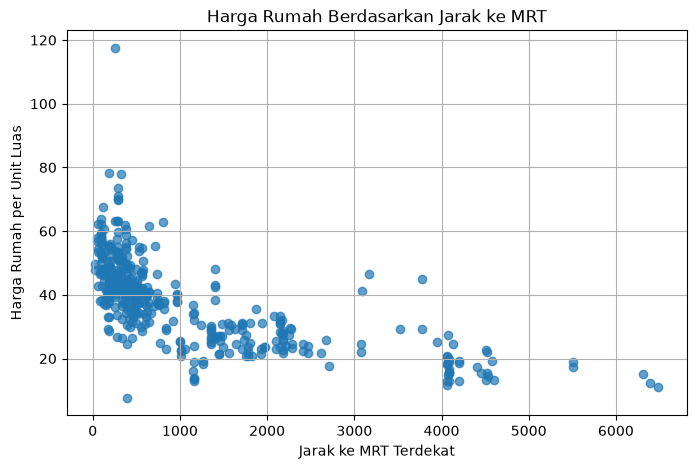

In [29]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['X3 distance to the nearest MRT station'],
    df['Y house price of unit area'],
    alpha=0.7
)

plt.title('Harga Rumah Berdasarkan Jarak ke MRT')
plt.xlabel('Jarak ke MRT Terdekat')
plt.ylabel('Harga Rumah per Unit Luas')
plt.grid(True)
plt.show()

Grafik scatter menunjukkan hubungan antara jarak ke stasiun MRT dan harga rumah per unit luas.

g.	Menampilkan Garis hasil prediksi dari machine learning pada Biaya Promosi terhadap penjualan (train set dan test set)

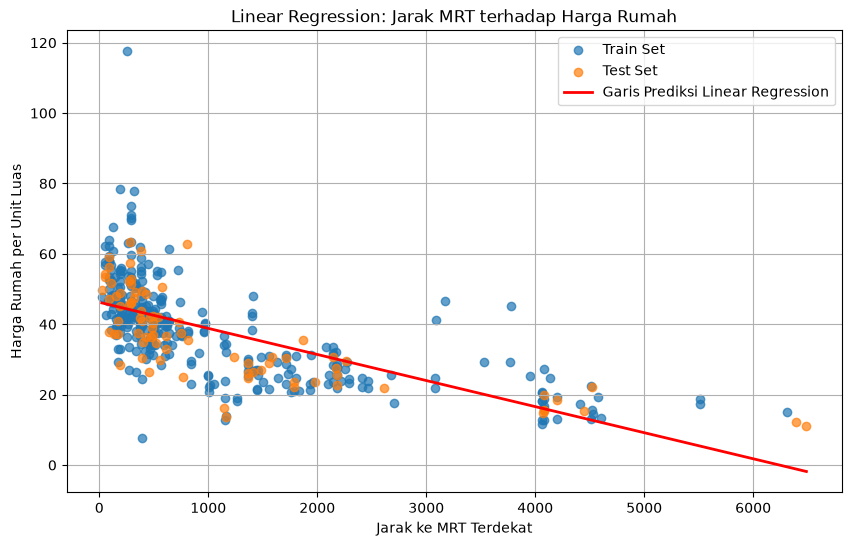

In [ ]:
plt.figure(figsize=(10, 6))
# Data training
plt.scatter(
    X_train.iloc[:, 0],
    y_train,
    label='Train Set',
    alpha=0.7
)
# Data testing
plt.scatter(
    X_test.iloc[:, 0],
    y_test,
    label='Test Set',
    alpha=0.7
)
# Garis regresi
X_garis = pd.DataFrame({
    'X3 distance to the nearest MRT station': np.linspace(
        df['X3 distance to the nearest MRT station'].min(),
        df['X3 distance to the nearest MRT station'].max(),
        200
    )
})
y_garis = model.predict(X_garis)
plt.plot(
    X_garis.iloc[:, 0],
    y_garis,
    color='red',
    linewidth=2,
    label='Garis Prediksi Linear Regression'
)
plt.title('Linear Regression: Jarak MRT terhadap Harga Rumah')
plt.xlabel('Jarak ke MRT Terdekat')
plt.ylabel('Harga Rumah per Unit Luas')
plt.legend()
plt.grid(True)
plt.show()

Titik menunjukkan data training dan testing, sedangkan garis merah menunjukkan hasil prediksi model Linear Regression.

### 2

In [31]:
from sklearn.metrics import r2_score

y_pred = model.predict(X_test)

print("a. Intercept:", model.intercept_)
print("b. Slope:", model.coef_[0])
print("c. R-Square:", r2_score(y_test, y_pred))

a. Intercept: 46.24269004533653
b. Slope: -0.00740951293493293
c. R-Square: 0.538959766501977


Intercept: 46.2427, yaitu nilai prediksi harga rumah ketika jarak ke MRT bernilai nol.



Slope: -0.00741, artinya setiap kenaikan satu unit jarak ke MRT, harga rumah yang diprediksi turun sekitar 0.00741 unit.



R-Square: 0.5390, artinya model menjelaskan sekitar 53.90% variasi harga rumah pada data testing.

### NO 3  dataset konsumen.csv yang berisikan informasi berupa No, Gaji, Pengeluaran. Buatlah sebuah code untuk klaterisasi gaji yang berhubungan dengan pengeluaran. 

# (NIM Ganjil) 017

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("konsumen.csv", sep=";")

print("Dataset berhasil dibaca.")

Dataset berhasil dibaca.


Kode membaca dataset konsumen menggunakan Pandas. Kolom yang digunakan dalam dataset adalah No, Gaji, dan Pengeluaran.

In [34]:
display(df.head(7))

,No,Gaji,Pengeluaran
0,1,2500,1750
1,2,3800,4200
2,3,3900,3800
3,4,4350,5500
4,5,4400,3200
5,6,5500,5450
6,7,5600,5950


head(7) menampilkan tujuh baris pertama untuk melihat contoh data konsumen sebelum dilakukan pengolahan.

In [33]:
df = df.drop(columns=["No"])

print("Kolom No berhasil dihapus.")
print(df.columns.tolist())

Kolom No berhasil dihapus.
['Gaji', 'Pengeluaran']


Kolom No dihapus karena hanya berfungsi sebagai nomor identitas konsumen dan tidak diperlukan dalam proses klasterisasi.

In [34]:
display(df.head(9))

,Gaji,Pengeluaran
0,2500,1750
1,3800,4200
2,3900,3800
3,4350,5500
4,4400,3200
5,5500,5450
6,5600,5950
7,5750,4100
8,6850,6050


Kode menampilkan sembilan baris pertama setelah kolom No dihapus. Data yang tersisa adalah Gaji dan Pengeluaran.

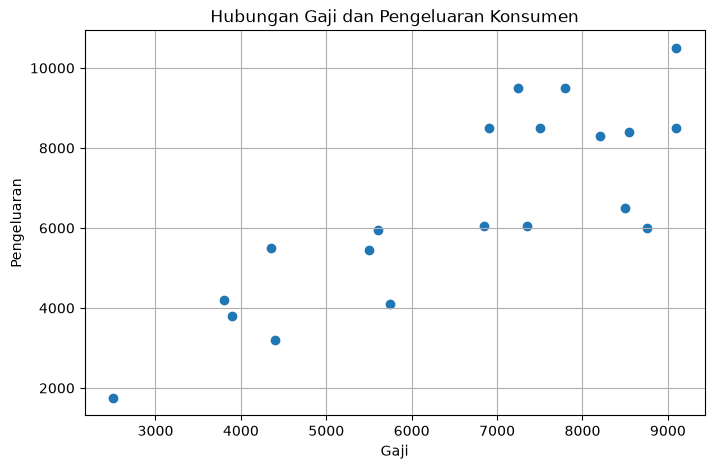

In [35]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Gaji"],
    df["Pengeluaran"]
)

plt.title("Hubungan Gaji dan Pengeluaran Konsumen")
plt.xlabel("Gaji")
plt.ylabel("Pengeluaran")
plt.grid(True)
plt.show()

Scatterplot digunakan untuk melihat hubungan antara gaji dan pengeluaran konsumen. Setiap titik mewakili satu konsumen.

In [36]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

X = df[["Gaji", "Pengeluaran"]]

# Normalisasi data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Membuat model K-Means dengan 2 klaster
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print("Hasil klasterisasi:")
display(df)

Hasil klasterisasi:


,Gaji,Pengeluaran,Cluster
0,2500,1750,0
1,3800,4200,0
2,3900,3800,0
3,4350,5500,0
4,4400,3200,0
5,5500,5450,0
6,5600,5950,0
7,5750,4100,0
8,6850,6050,1
9,6900,8500,1


K-Means membagi konsumen menjadi dua kelompok berdasarkan kemiripan nilai gaji dan pengeluaran. StandardScaler digunakan agar kedua fitur memiliki skala yang sebanding saat menghitung jarak.

In [37]:
centers = scaler.inverse_transform(
    kmeans.cluster_centers_
)

centers_df = pd.DataFrame(
    centers,
    columns=["Gaji", "Pengeluaran"]
)

print("Pusat masing-masing klaster:")
display(centers_df)

Pusat masing-masing klaster:


,Gaji,Pengeluaran
0,4475.0,4243.75
1,7987.5,8025.00


Pusat klaster (centroid) merupakan titik pusat dari masing-masing kelompok konsumen. Nilai ditampilkan kembali dalam skala asli gaji dan pengeluaran agar mudah diinterpretasikan.

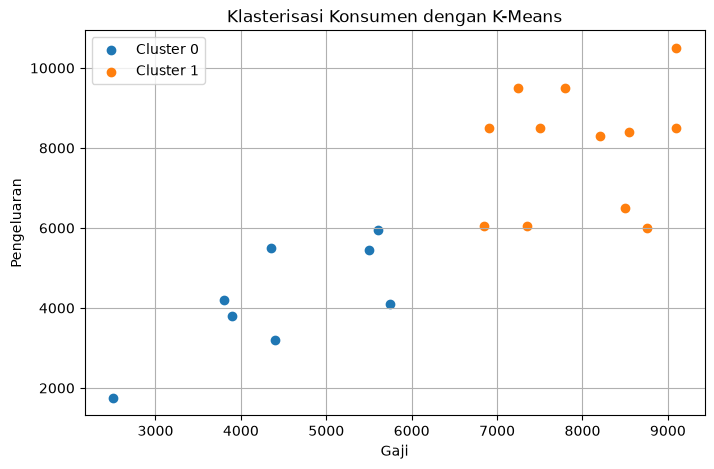

In [38]:
plt.figure(figsize=(8, 5))

for cluster in sorted(df["Cluster"].unique()):
    data_cluster = df[df["Cluster"] == cluster]

    plt.scatter(
        data_cluster["Gaji"],
        data_cluster["Pengeluaran"],
        label=f"Cluster {cluster}"
    )

plt.title("Klasterisasi Konsumen dengan K-Means")
plt.xlabel("Gaji")
plt.ylabel("Pengeluaran")
plt.legend()
plt.grid(True)
plt.show()

Grafik membedakan konsumen berdasarkan klaster menggunakan warna yang berbeda. Dengan demikian, pembagian konsumen ke dalam dua kelompok dapat terlihat secara visual.

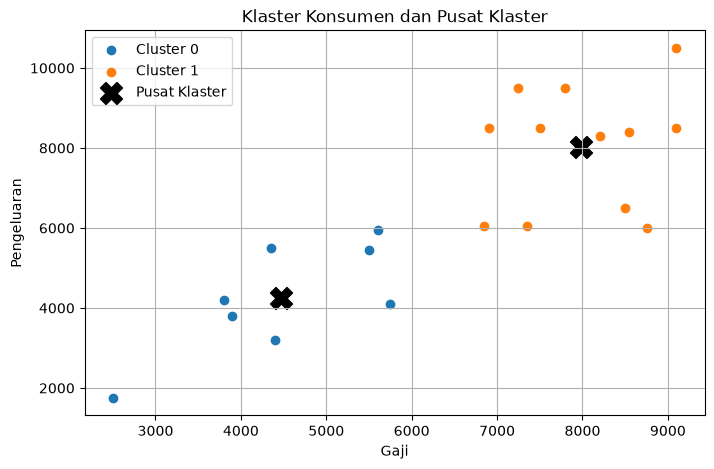

In [39]:
plt.figure(figsize=(8, 5))

for cluster in sorted(df["Cluster"].unique()):
    data_cluster = df[df["Cluster"] == cluster]

    plt.scatter(
        data_cluster["Gaji"],
        data_cluster["Pengeluaran"],
        label=f"Cluster {cluster}"
    )

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=250,
    color="black",
    label="Pusat Klaster"
)

plt.title("Klaster Konsumen dan Pusat Klaster")
plt.xlabel("Gaji")
plt.ylabel("Pengeluaran")
plt.legend()
plt.grid(True)
plt.show()

Grafik ini menampilkan dua kelompok konsumen dengan warna berbeda dan tanda silang hitam (X) sebagai pusat klaster. Pusat tersebut menunjukkan posisi rata-rata kelompok berdasarkan gaji dan pengeluaran.